In [1]:
import sys
sys.path.append("..")

import pandas as pd
from features.pipeline import load_sequence

path = "../data/kaggle/train_landmark_files/16069/100015657.parquet"
arr = load_sequence(path)
print(arr.shape)

raw = pd.read_parquet(path)
print(raw[raw["frame"] == raw["frame"].min()]["type"].iloc[[0, 467, 468, 488, 489, 521, 522, 542]].tolist())

(105, 543, 3)
['face', 'face', 'left_hand', 'left_hand', 'pose', 'pose', 'right_hand', 'right_hand']


In [1]:
import sys
sys.path.append("..")
import numpy as np
from features.pipeline import load_sequence, select_landmarks
from features.landmarks import N_POINTS, DOM_HAND_BLOCK, NONDOM_HAND_BLOCK

path = "../data/kaggle/train_landmark_files/16069/100015657.parquet"
sel = select_landmarks(load_sequence(path))
print(sel.shape, N_POINTS)
print("Right hand all NaN:", np.isnan(sel[:, DOM_HAND_BLOCK]).all())
print("Left hand NaN frames:", np.isnan(sel[:, NONDOM_HAND_BLOCK, 0]).all(axis=1).sum())

(105, 94, 3) 94
Right hand all NaN: True
Left hand NaN frames: 77


In [1]:
import sys
sys.path.append("..")
import numpy as np
from features.pipeline import load_sequence, select_landmarks, flip, make_right_dominant
from features.landmarks import DOM_HAND_BLOCK, NONDOM_HAND_BLOCK

for p in ["16069/100015657", "26734/1001931356", "2044/1021210853"]:
    sel = select_landmarks(load_sequence(f"../data/kaggle/train_landmark_files/{p}.parquet"))
    out, flipped = make_right_dominant(sel)
    dom = (~np.isnan(out[:, DOM_HAND_BLOCK.start, 0])).sum()
    nondom = (~np.isnan(out[:, NONDOM_HAND_BLOCK.start, 0])).sum()
    print(p, "flipped:", flipped, "| dominant visible:", dom, "| non-dominant visible:", nondom)
    print("   flip twice == original:", np.allclose(flip(flip(sel)), sel, equal_nan=True))

16069/100015657 flipped: True | dominant visible: 28 | non-dominant visible: 0
   flip twice == original: True
26734/1001931356 flipped: False | dominant visible: 146 | non-dominant visible: 0
   flip twice == original: True
2044/1021210853 flipped: False | dominant visible: 8 | non-dominant visible: 0
   flip twice == original: True


In [1]:
import sys
sys.path.append("..")
import numpy as np
from features.pipeline import load_sequence, select_landmarks, make_right_dominant, normalize
from features.landmarks import NOSE, L_SHOULDER, R_SHOULDER, DOM_HAND_BLOCK

for p in ["16069/100015657", "26734/1001931356", "2044/1021210853"]:
    sel = select_landmarks(load_sequence(f"../data/kaggle/train_landmark_files/{p}.parquet"))
    sel, _ = make_right_dominant(sel)
    norm = normalize(sel)
    mid = (norm[:, L_SHOULDER] + norm[:, R_SHOULDER]) / 2
    d = np.linalg.norm(norm[:, NOSE, :2] - mid[:, :2], axis=-1)
    print(p, "| mid x,y:", np.round(np.nanmean(mid[:, :2], axis=0), 3), "| nose dist:", round(float(np.nanmean(d)), 3))
    print("   dominant wrist x,y range:", np.round(np.nanmin(norm[:, DOM_HAND_BLOCK.start, :2], axis=0), 2), np.round(np.nanmax(norm[:, DOM_HAND_BLOCK.start, :2], axis=0), 2))

16069/100015657 | mid x,y: [0. 0.] | nose dist: 1.0
   dominant wrist x,y range: [-2.08 -0.79] [-1.57  0.14]
26734/1001931356 | mid x,y: [0. 0.] | nose dist: 1.0
   dominant wrist x,y range: [-1.93 -0.84] [-1.02  0.07]
2044/1021210853 | mid x,y: [-0.  0.] | nose dist: 1.0
   dominant wrist x,y range: [-1.82 -0.03] [-0.73  0.74]


In [1]:
import sys
sys.path.append("..")
import numpy as np
from features.pipeline import process_sequence

for p in ["16069/100015657", "26734/1001931356", "2044/1021210853"]:
    f = process_sequence(f"../data/kaggle/train_landmark_files/{p}.parquet")
    print(p, f.shape, f.dtype, "| any NaN:", np.isnan(f).any(), "| dom flag sum:", int(f[:, -2].sum()), "| nondom flag sum:", int(f[:, -1].sum()))

16069/100015657 (105, 320) float32 | any NaN: False | dom flag sum: 28 | nondom flag sum: 0
26734/1001931356 (225, 320) float32 | any NaN: False | dom flag sum: 146 | nondom flag sum: 0
2044/1021210853 (16, 320) float32 | any NaN: False | dom flag sum: 8 | nondom flag sum: 0


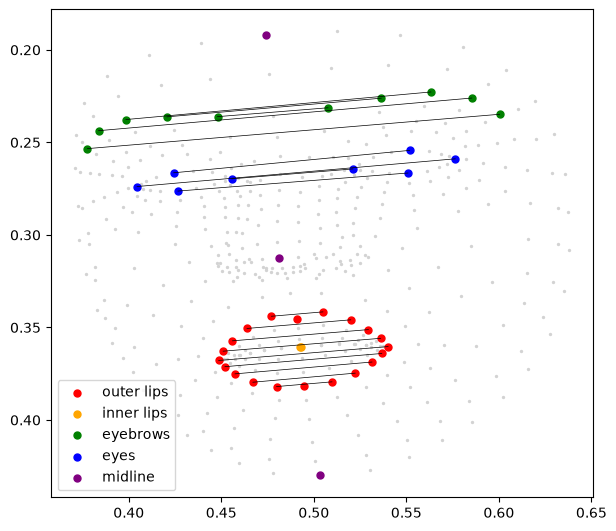

In [7]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
from features.pipeline import load_sequence
from features.landmarks import FACE_START, LIPS_OUTER, LIPS_INNER, EYEBROWS, EYES, MIDLINE, FACE_PAIRS

arr = load_sequence("../data/kaggle/train_landmark_files/26734/1001931356.parquet")
face = arr[0, FACE_START:FACE_START + 468]

plt.figure(figsize=(7, 7))
plt.scatter(face[:, 0], face[:, 1], s=2, c="lightgrey")
groups = [("outer lips", LIPS_OUTER, "red"), ("inner lips", LIPS_INNER, "orange"),
          ("eyebrows", EYEBROWS, "green"), ("eyes", EYES, "blue"), ("midline", MIDLINE, "purple")]
for name, idx, colour in groups:
    plt.scatter(face[idx, 0], face[idx, 1], s=25, c=colour, label=name)
for p, q in FACE_PAIRS:
    plt.plot([face[p, 0], face[q, 0]], [face[p, 1], face[q, 1]], c="black", lw=0.5)
plt.gca().invert_yaxis()
plt.gca().set_aspect("equal")
plt.legend()
plt.savefig("../docs/figures/face_indices.png", dpi=150, bbox_inches="tight")
plt.show()

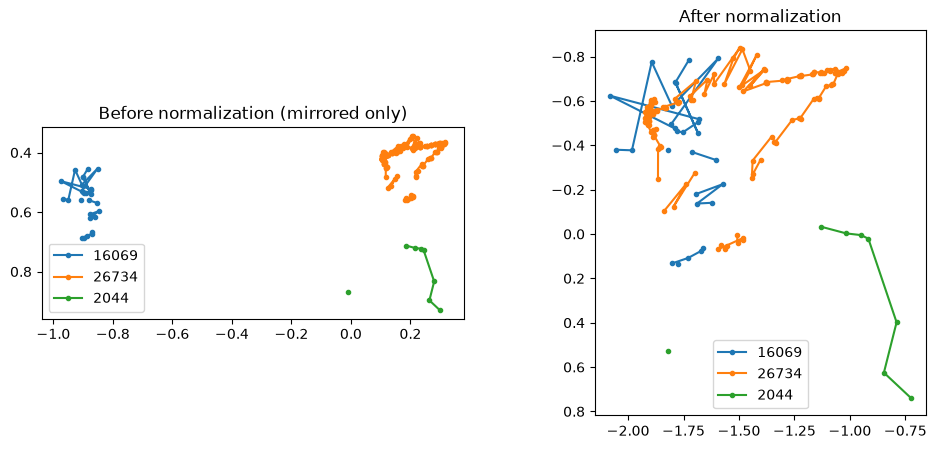

In [6]:
import numpy as np
from features.pipeline import select_landmarks, make_right_dominant, normalize
from features.landmarks import DOM_HAND_BLOCK

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for p in ["16069/100015657", "26734/1001931356", "2044/1021210853"]:
    sel = select_landmarks(load_sequence(f"../data/kaggle/train_landmark_files/{p}.parquet"))
    sel, _ = make_right_dominant(sel)
    raw = sel[:, DOM_HAND_BLOCK.start, :2]
    norm = normalize(sel)[:, DOM_HAND_BLOCK.start, :2]
    who = p.split("/")[0]
    axes[0].plot(raw[:, 0], raw[:, 1], marker="o", ms=3, label=who)
    axes[1].plot(norm[:, 0], norm[:, 1], marker="o", ms=3, label=who)

for ax, title in zip(axes, ["Before normalization (mirrored only)", "After normalization"]):
    ax.invert_yaxis()
    ax.set_aspect("equal")
    ax.set_title(title)
    ax.legend()
fig.savefig("../docs/figures/normalization_check.png", dpi=150, bbox_inches="tight")
plt.show()